In [1]:
import pandas as pd

# 1. Cargamos el archivo de Excel
datos_bogota = pd.read_excel("accidentes.xlsx")

# 2. Seleccionamos únicamente las columnas que nos sirven para modelar el riesgo
columnas_proyecto = ["FECHA", "HORA", "GRAVEDAD", "CLASE"]
datos_limpios = datos_bogota[columnas_proyecto]

# 3. Eliminamos filas que puedan estar vacías por error
datos_limpios = datos_limpios.dropna()

# 4. Mostramos las primeras 5 filas de nuestra nueva tabla limpia
datos_limpios.head()

,FECHA,HORA,GRAVEDAD,CLASE
0,01/01/2015,01:05:00,2,2
1,01/01/2015,05:50:00,2,3
2,01/01/2015,07:15:00,2,3
3,01/01/2015,09:30:00,3,1
4,01/01/2015,09:45:00,2,1


In [2]:
# 1. Le decimos a Python que extraiga solo los primeros dos dígitos de la columna HORA (es decir, la hora sin minutos)
# Ejemplo: "01:05:00" se convertirá simplemente en el número 1
datos_limpios['HORA_NUMERICA'] = datos_limpios['HORA'].astype(str).str[:2].astype(int)

# 2. Contamos cuántos accidentes ocurren en cada una de las 24 horas del día
accidentes_por_hora = datos_limpios.groupby('HORA_NUMERICA').size().reset_index(name='TOTAL_ACCIDENTES')

# 3. Mostramos la nueva tabla agrupada para ver el comportamiento
accidentes_por_hora


,HORA_NUMERICA,TOTAL_ACCIDENTES
0,0,2363
1,1,1747
2,2,1559
3,3,1895
4,4,2329
5,5,5564
6,6,9548
7,7,11605
8,8,10996
9,9,10086


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.3 MB/s eta 0:00:03
   ---- ----------------------------------- 1.0/9.5 MB 2.5 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.5 MB 2.8 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 3.2 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.5 MB 3.0 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.5 MB 2.9 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 2.6 MB/s eta 0:00:03
   ----------------- ---------------------- 4.2/9.5 MB 2.5 MB/s eta 0:00:03
   ------------------- -------------------- 4.7/9.5 MB 2.5 MB/s eta 0:00:02
   ---------------------- ----------------- 5.2/9.5 MB 2.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 2.4 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.5 MB 2.4 MB/s eta 0:00:02
   ----------------

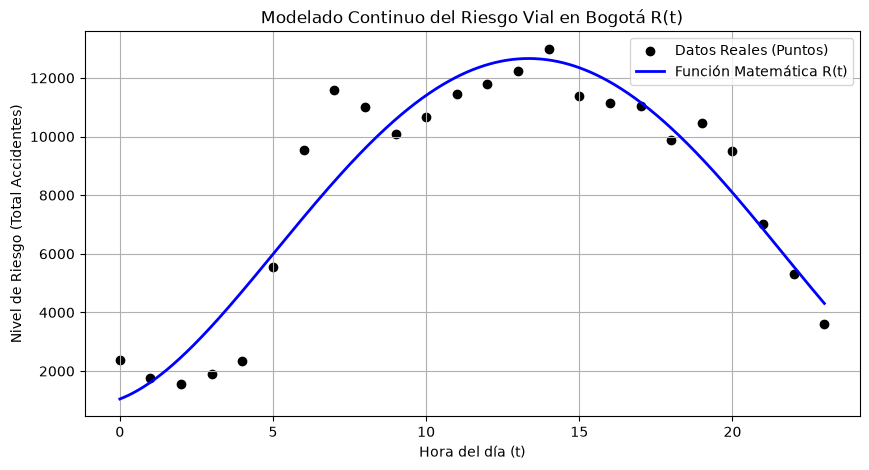

Tu función matemática continua R(t) es:
        4         3       2
0.2814 x - 15.04 x + 186 x + 399.1 x + 1047


In [4]:
%pip install matplotlib numpy sympy

import numpy as np
import matplotlib.pyplot as plt

# 1. Definimos las variables X (horas) e Y (total de accidentes) usando tus datos
X = accidentes_por_hora['HORA_NUMERICA'].values
Y = accidentes_por_hora['TOTAL_ACCIDENTES'].values

# 2. Le pedimos a Python que halle un polinomio de Grado 4 que dibuje una curva suave sobre los puntos
coeficientes = np.polyfit(X, Y, 4)
funcion_riesgo = np.poly1d(coeficientes)

# 3. Dibujamos la gráfica para ver los puntos reales frente a la curva matemática continua
plt.figure(figsize=(10, 5))
plt.scatter(X, Y, color='black', label='Datos Reales (Puntos)')
x_curva = np.linspace(0, 23, 500)
plt.plot(x_curva, funcion_riesgo(x_curva), color='blue', linewidth=2, label='Función Matemática R(t)')

plt.title('Modelado Continuo del Riesgo Vial en Bogotá R(t)')
plt.xlabel('Hora del día (t)')
plt.ylabel('Nivel de Riesgo (Total Accidentes)')
plt.legend()
plt.grid(True)
plt.show()

# 4. Imprimimos en pantalla la ecuación matemática resultante
print("Tu función matemática continua R(t) es:")
print(funcion_riesgo)


In [3]:
import pandas as pd
import numpy as np
import sympy as sp

# 1. Cargamos y agrupamos los datos
datos_bogota = pd.read_excel("accidentes.xlsx")
datos_limpios = datos_bogota[["HORA"]].dropna()
datos_limpios['HORA_NUMERICA'] = datos_limpios['HORA'].astype(str).str[:2].astype(int)
accidentes_por_hora = datos_limpios.groupby('HORA_NUMERICA').size().reset_index(name='TOTAL_ACCIDENTES')

X = accidentes_por_hora['HORA_NUMERICA'].values
Y = accidentes_por_hora['TOTAL_ACCIDENTES'].values

# 2. Coeficientes
coeficientes = np.polyfit(X, Y, 4)

# 3. Función simbólica R(t)
t = sp.Symbol('t')
a, b, c, d, e = coeficientes
R = a*t**4 + b*t**3 + c*t**2 + d*t + e

# 4. Primera derivada R'(t)
R_derivada = sp.diff(R, t)

# 5. Encontrar puntos críticos
puntos_criticos = sp.solve(R_derivada, t)

print("--- RESULTADOS DEL MOTOR MATEMÁTICO ---")
print(f"Ecuación del Riesgo R(t):\n{sp.pretty(sp.N(R, 4))}\n")
print(f"Primera Derivada R'(t):\n{sp.pretty(sp.N(R_derivada, 4))}\n")

# 6. CORRECCIÓN: Filtramos las raíces convirtiéndolas a números reales de Python de forma segura
hora_critica_val = 0
for p in puntos_criticos:
    p_complejo = complex(p) # Convertimos a formato numérico estándar
    if abs(p_complejo.imag) < 1e-5: # Si no tiene parte imaginaria (es real)
        p_real = p_complejo.real
        if 0 <= p_real <= 23: # Si está dentro de las 24 horas del día
            hora_critica_val = p_real
            break

# Convertimos a formato de reloj (horas:minutos)
horas_enteras = int(hora_critica_val)
minutos = int((hora_critica_val - horas_enteras) * 60)

# Calculamos el despacho preventivo (30 minutos antes)
total_minutos_alerta = (horas_enteras * 60 + minutos) - 30
horas_alerta = total_minutos_alerta // 60
minutos_alerta = total_minutos_alerta % 60

print("--- INFORME DE ALERTAS PREVENTIVAS ---")
print(f"El Máximo Absoluto matemático ocurre exactamente a las: {horas_enteras}:{minutos:02d}")
print(f"Ventana de anticipación para despacho preventivo: {horas_alerta}:{minutos_alerta:02d}")




--- RESULTADOS DEL MOTOR MATEMÁTICO ---
Ecuación del Riesgo R(t):
        4          3          2                   
0.2814⋅t  - 15.04⋅t  + 186.0⋅t  + 399.1⋅t + 1047.0

Primera Derivada R'(t):
       3          2                  
1.126⋅t  - 45.13⋅t  + 371.9⋅t + 399.1

--- INFORME DE ALERTAS PREVENTIVAS ---
El Máximo Absoluto matemático ocurre exactamente a las: 13:20
Ventana de anticipación para despacho preventivo: 12:50
